In [2]:
import numpy as np
import pandas as pd
import scipy.sparse as sparse
import itertools
import matplotlib
from matplotlib import cm
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm, LinearSegmentedColormap
from datetime import date
import re
# from tqdm import tqdm
import time
# from pybedtools import BedTool
import random
import math
import pickle
import seaborn as sns
from scipy.stats import percentileofscore, pearsonr, rankdata, describe, mode, fisher_exact
import scipy as sp
import scipy.stats as stats
from scipy.spatial.distance import jaccard, euclidean, cosine, pdist
# import functools
# import operator
import gzip
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity, euclidean_distances
from sklearn.metrics import pairwise_distances
import sys
import os
from functools import partial
from contextlib import closing
from multiprocessing import Pool
import re
import h5py
import tabix
import upsetplot
from wordcloud import WordCloud
from sklearn.decomposition import NMF, non_negative_factorization
from collections import Counter
from scipy.stats import hypergeom
from scipy.stats.mstats import gmean
from scipy.cluster import hierarchy
import squarify
try:
    import piplite
    await piplite.install(['ipywidgets'])
except ImportError:
    pass
import ipywidgets as widgets
import json
from subprocess import Popen, PIPE
import requests

today = date.today()

**Functions**

In [9]:
# order = 4
# datadir = '/home/ctrader/region_similarity/data/rank_based/hilbert/'
# in_f = datadir + 'hilbert_regions_order_{}_CT20230606.DHS.factornormNMF.sum_enrich_corank.epilogos.statesum_rank.percentiles.hdf5'.format(order)

# hdf5_f = h5py.File(in_f, 'r')
# order_4_coords = np.char.decode(hdf5_f['coordinates'][:])
# hdf5_f.close()

In [114]:
# order = 7
# datadir = '/home/ctrader/region_similarity/data/rank_based/hilbert/'
# in_f = datadir + 'hilbert_regions_order_{}_CT20230606.DHS.factornormNMF.sum_enrich_corank.epilogos.statesum_rank.percentiles.hdf5'.format(order)

# hdf5_f = h5py.File(in_f, 'r')
# order_7_coords = np.char.decode(hdf5_f['coordinates'][:])
# hdf5_f.close()

In [2]:
chr_start_ind_dict = {}
for order in [4, 5, 6, 7, 8, 9, 10, 11]:
    print(order)
    datadir = '/home/ctrader/region_similarity/data/rank_based/hilbert/'
    in_f = datadir + 'hilbert_regions_order_{}_CT20230606.DHS.factornormNMF.sum_enrich_corank.epilogos.statesum_rank.percentiles.hdf5'.format(order)

    hdf5_f = h5py.File(in_f, 'r')
    order_coords = np.char.decode(hdf5_f['coordinates'][:])
    hdf5_f.close()
    
    chr_start_ind_dict[order] = np.unique(order_coords[:, 0], return_index=True)[1]

4
5
6
7
8
9
10
11


In [3]:
"""
Converts hilbert curve inds across scales. Takes in a starting order, a starting segment index, 
and a desired hilbert order. Returns the overlapping indices in the desired order
"""
def order_ind_conv(start_ind, start_o, end_o):
    # difference in orders
    o_diff = end_o - start_o
    # relative size of starting segment to ending segment
    seg_multiplier = 4**o_diff

    # find chromosome offset values for each order
    # due to non-linear differences in number of segments per chromosome
    offset_mask = chr_start_ind_dict[start_o] <= start_ind
    start_o_offset = chr_start_ind_dict[start_o][offset_mask][-1]
    end_o_offset = chr_start_ind_dict[end_o][offset_mask][-1]

    # correct starting ind
    start_ind_offset = start_ind - start_o_offset
    
    # find mapped end inds
    end_inds_offset = np.arange((seg_multiplier * start_ind_offset), (seg_multiplier * (start_ind_offset + 1)), dtype=int)
    # correct end inds
    end_inds = end_inds_offset + end_o_offset
    
    return end_inds

In [4]:
order_ind_conv(2810, 4, 7)

array([179136, 179137, 179138, 179139, 179140, 179141, 179142, 179143,
       179144, 179145, 179146, 179147, 179148, 179149, 179150, 179151,
       179152, 179153, 179154, 179155, 179156, 179157, 179158, 179159,
       179160, 179161, 179162, 179163, 179164, 179165, 179166, 179167,
       179168, 179169, 179170, 179171, 179172, 179173, 179174, 179175,
       179176, 179177, 179178, 179179, 179180, 179181, 179182, 179183,
       179184, 179185, 179186, 179187, 179188, 179189, 179190, 179191,
       179192, 179193, 179194, 179195, 179196, 179197, 179198, 179199])

**Data**

In [14]:
# example_data = []
# for i in range(0, 1048576, 2000):
#     example_data.append(['chr1', str(i), str(i+1), 'test1'])
# for i in range(0, 1048576, 3000):
#     example_data.append(['chr1', str(i), str(i+1), 'test2'])
    
# for i in range(1048576, 1048576 * 2, 4000):
#     example_data.append(['chr1', str(i), str(i+1), 'test1'])
# for i in range(1048576, 1048576 * 2, 2000):
#     example_data.append(['chr1', str(i), str(i+1), 'test2'])
    
# for i in range(1048576 *2 , 1048576 * 3, 8000):
#     example_data.append(['chr1', str(i), str(i+1), 'test1'])
# for i in range(1048576 * 2, 1048576 * 3, 1000):
#     example_data.append(['chr1', str(i), str(i+1), 'test2'])

In [17]:
# np.savetxt('/home/ctrader/hilbert/data/test/testdata_CT20230620.bed', example_data, fmt='%s', delimiter='\t')

In [21]:
def load_factors(per_f):
    hdf5_f = h5py.File(per_f, 'r')
    factors = np.char.decode(hdf5_f['factors'][:])
    color = np.char.decode(hdf5_f['colors'][:])
    hdf5_f.close()
    return factors, color

datadir = '/home/ctrader/region_similarity/data/rank_based/'
DHS_per_f = datadir + 'regions_1kb_CT20230427.DHS.factornormNMF.sum_enrich_corank_percentile.hdf5'
epi_per_f = datadir + 'regions_1kb_CT20230427.epilogos.statesum_rank_percentile.hdf5'

# load region percentiles
DHS_factors, DHS_color = load_factors(DHS_per_f)
epi_factors, epi_color = load_factors(epi_per_f)

factor_order = np.append(DHS_factors, epi_factors)
color_order = np.append(DHS_color, epi_color)

color_order[np.where(factor_order == 'Quies')[0]] = '#e0e0e0'

**Narration rank results**

In [59]:
# all_order_sparsity = []

all_order_top_factor_regions = {}
for order in [4, 5, 6, 7, 8, 9, 10, 11]:
    print(order)
    datadir = '/home/ctrader/region_similarity/data/rank_based/hilbert/'
    in_f = datadir + 'hilbert_regions_order_{}_CT20230606.DHS.factornormNMF.sum_enrich_corank.epilogos.statesum_rank.percentiles.hdf5'.format(order)

    hdf5_f = h5py.File(in_f, 'r')
    order_ranks = hdf5_f['percentiles'][:]
    order_coords = np.char.decode(hdf5_f['coordinates'][:])
    hdf5_f.close()
    
    
    top_factor_regions = order_coords[np.argmax(order_ranks, axis=0)]
    order_dict = {}
    for r, factor in zip(top_factor_regions, range(len(top_factor_regions))):
        region = r[0] + ':' + r[1] + '-' + r[2]
        order_dict[factor] = region
    all_order_top_factor_regions[order] = order_dict
    
#     sparsity = np.count_nonzero(order_ranks, axis=0) / len(order_ranks)
#     all_order_sparsity.append(sparsity)
    
# all_order_sparsity = np.array(all_order_sparsity)

4
5
6
7
8
9
10
11


In [61]:
datadir = '/home/ctrader/region_similarity/data/rank_based/hilbert'
filepath = os.path.join(datadir, 'hilbert_orders_4t11.top_regions_per_factor.CT20230626.json')
with open(filepath, 'w') as file:
    json.dump(all_order_top_factor_regions, file)

In [57]:
    top_factor_regions = order_coords[np.argmax(order_ranks, axis=0)]

    order_dict = {}
    for r, factor in zip(top_factor_regions, range(len(top_factor_regions))):
        region = r[0] + ':' + r[1] + '-' + r[2]
        order_dict[factor] = region

In [58]:
order_dict

{0: 'chr19:52428800-53477376',
 1: 'chr6:32505856-33554432',
 2: 'chr6:6291456-7340032',
 3: 'chr4:173015040-174063616',
 4: 'chr10:128974848-130023424',
 5: 'chr15:38797312-39845888',
 6: 'chr1:29360128-30408704',
 7: 'chr5:88080384-89128960',
 8: 'chr18:22020096-23068672',
 9: 'chr15:38797312-39845888',
 10: 'chr9:115343360-116391936',
 11: 'chr7:46137344-47185920',
 12: 'chr1:152043520-153092096',
 13: 'chr18:75497472-76546048',
 14: 'chr7:1048576-2097152',
 15: 'chr19:57671680-58617616',
 16: 'chr11:65011712-66060288',
 17: 'chr6:27262976-28311552',
 18: 'chr11:65011712-66060288',
 19: 'chr9:136314880-137363456',
 20: 'chr22:40894464-41943040',
 21: 'chr1:155189248-156237824',
 22: 'chr19:1048576-2097152',
 23: 'chr19:1048576-2097152',
 24: 'chr14:68157440-69206016',
 25: 'chr14:68157440-69206016',
 26: 'chr16:84934656-85983232',
 27: 'chr19:36700160-37748736',
 28: 'chr19:22020096-23068672',
 29: 'chr7:26214400-27262976',
 30: 'chr12:53477376-54525952',
 31: 'chr10:100663296-10171

Text(0.5, 0.92, 'Factor Density at Each Order')

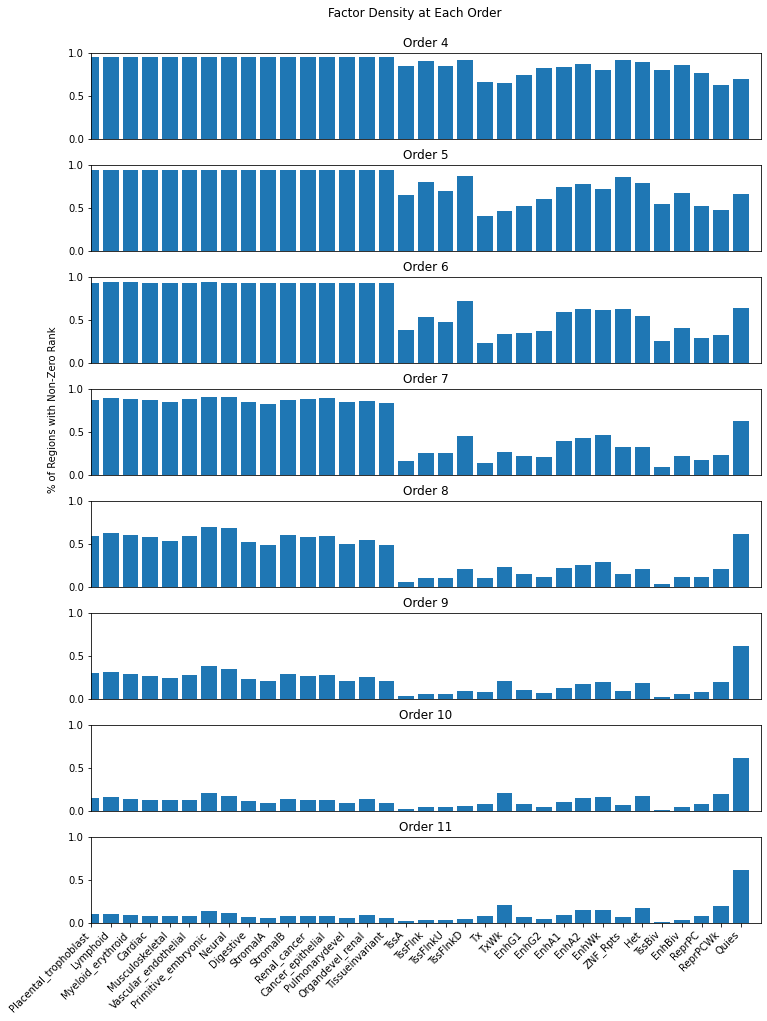

In [37]:
# bar chart showing sparsity of each factor at each order
fig, axes = plt.subplots(len(all_order_sparsity), 1, figsize=(12, 16))  
fig.patch.set_facecolor('white')
plt.subplots_adjust(hspace=0.3)

axes.ravel()

for ax, sparsity, order in zip(axes, all_order_sparsity, np.arange(4, 12)):
    ax.bar(np.arange(len(sparsity)), sparsity)
    
#     if scale == '1':
#         ax.legend(['Full Dataset', 'Subset Search Space'], loc=(0.79, 1.01))
    
    ax.set_ylim([0, 1])
    ax.set_xlim([0, len(sparsity)])
    
    ax.set_yticks([0, 0.5, 1])
    
    ax.set_xticks([])
    ax.set_title('Order ' + str(order))
    
axes[-1].set_xticks(np.arange(len(factor_order)))
axes[-1].set_xticklabels(factor_order, rotation=45, ha='right')

fig.text(0.075, 0.5, '% of Regions with Non-Zero Rank', rotation=90)



fig.suptitle('Factor Density at Each Order', y=0.92)

**SFC results**

In [ ]:
# checking to make sure we get the same results with <= that we do with < in SFC calculation

In [3]:
os.path.join(datadir, 'order_9_windows_annotation_sfc_scores.txt.gz')

'/home/ctrader/hilbert/results/TF/20230707/order_9_windows_annotation_sfc_scores.txt.gz'

In [4]:
datadir = '/home/ctrader/hilbert/results/TF/20230707'
path = os.path.join(datadir, 'order_9_windows_annotation_sfc_scores.txt.gz')
lte = np.loadtxt(path, skiprows=1, usecols=np.arange(3, 282 + 3), delimiter='\t', dtype=float)

In [5]:
ltdatadir = '/home/ctrader/hilbert/results/TF/20230622'
ltpath = os.path.join(ltdatadir, 'order_9_windows_annotation_sfc_scores.txt.gz')
lt = np.loadtxt(ltpath, skiprows=1, usecols=np.arange(3, 282 + 3), delimiter='\t', dtype=float)

In [16]:
lte[lte != lt]

array([], dtype=float64)

In [ ]:
# checking to make sure parallelization results match results from before

In [145]:
chrm='Y'

datadir = '/home/ctrader/hilbert/results/TF/20230621/4'
f = open(os.path.join(datadir, 'chr{}.json'.format(chrm)))
after = json.load(f)
f.close()

datadir = '/home/ctrader/hilbert/results/TF/JQ/20230608'
f = open(os.path.join(datadir, 'chr{}.json'.format(chrm)))
before = json.load(f)
f.close()

In [146]:
b_c = before['chromosome']
b_o = before['order']
b_min = before['min']
b_max = before['max']
b_fields = before['fields']
b_dtype = before['dtype']
b_shape = before['shape']
b_size = before['size']
b_bytes = before['bytes']
b_bytes_per_value = before['bytes_per_value']

a_c = after['chromosome']
a_o = after['order']
a_min = after['min']
a_max = after['max']
a_fields = after['fields']
a_dtype = after['dtype']
a_shape = after['shape']
a_size = after['size']
a_bytes = after['bytes']
a_bytes_per_value = after['bytes_per_value']

In [147]:
print('chromosome\t', a_c==b_c)
print('order\t', a_o==b_o)
print('min\t', a_min[1:]==b_min)
print('max\t', a_max[1:]==b_max)
print('fields\t', a_fields[1:]==b_fields)
print('dtype\t', a_dtype==b_dtype)
print('bpv\t', a_bytes_per_value==b_bytes_per_value)
print()
print('shape\t', a_shape==b_shape, a_shape, b_shape)
print('size\t', a_size==b_size, a_size, b_size)
print('bytes\t', a_bytes==b_bytes, a_bytes, b_bytes)



chromosome	 True
order	 True
min	 True
max	 True
fields	 True
dtype	 True
bpv	 True

shape	 False [55, 283] [55, 282]
size	 False 15565 15510
bytes	 False 62260 62040


DHS

In [185]:
thresh = 1

In [186]:
# kde plot showing the number of segments with a value at each order 
dhs_segment_fraction_nonzero = []
dhs_persegment_numfactors_nonzero = []

dhs_segment_fraction_gt_thresh = []
dhs_persegment_numfactors_gt_thresh = []

dhs_maxaverage = []
dhs_maxaverage_gt_thresh = []
for order in range(4, 13):
    t = time.time()
    filename = '/home/ctrader/hilbert/results/DHS/20230622/order_{}_windows_annotation_sfc_scores.txt.gz'.format(order)
    sfc = pd.read_csv(filename, delimiter='\t', usecols=np.arange(3, 16 + 3), dtype=np.float16)
    sfc = np.where(sfc < 0, 0, sfc)
    
    # number of segments with significant factors
    segment_nonzero = np.count_nonzero(sfc > 0, axis=1)
    dhs_persegment_numfactors_nonzero.append(segment_nonzero)
    all_nonzero = np.count_nonzero(segment_nonzero) / len(segment_nonzero)
    dhs_segment_fraction_nonzero.append(all_nonzero)
    
    # number of segments with significance > thresh
    segment_gt_thresh = np.count_nonzero(sfc > thresh, axis=1)
    dhs_persegment_numfactors_gt_thresh.append(segment_gt_thresh)
    all_gt_thresh = np.count_nonzero(segment_gt_thresh) / len(segment_gt_thresh)
    dhs_segment_fraction_gt_thresh.append(all_gt_thresh)
    
    
    # average sfc value for order
    order_max = np.max(sfc, axis=1)
    order_maxave = np.mean(order_max)
    dhs_maxaverage.append(order_maxave)
    
    # average sfc value (of those > thresh) for order
    order_maxave = np.mean(order_max[order_max > thresh])
    dhs_maxaverage_gt_thresh.append(order_maxave)
    
    del sfc
    print(order, time.time() - t)
dhs_segment_fraction_nonzero = np.array(dhs_segment_fraction_nonzero)

4 0.014629364013671875
5 0.030203819274902344
6 0.0951547622680664
7 0.32145094871520996
8 1.2379302978515625
9 4.870718479156494
10 19.80405879020691
11 80.26838159561157
12 323.9309537410736


TF Motifs

In [5]:
# # kde plot showing the number of segments with a value at each order 
# tf_segment_fraction_nonzero = []
# tf_persegment_numfactors_nonzero = []
# tf_maxaverage = []
# for order in range(4, 12):
#     t = time.time()
#     filename = '/home/ctrader/hilbert/results/TF/20230622/order_{}_windows_annotation_sfc_scores.txt.gz'.format(order)
#     sfc = pd.read_csv(filename, delimiter='\t', usecols=np.arange(3, 282 + 3), dtype=np.float16)
#     sfc = np.where(sfc < 0, 0, sfc)
    
#     # number of segments with significant factors
#     segment_nonzero = np.count_nonzero(sfc > 0, axis=1)
#     tf_persegment_numfactors_nonzero.append(segment_nonzero)
#     all_nonzero = np.count_nonzero(segment_nonzero) / len(segment_nonzero)
#     tf_segment_fraction_nonzero.append(all_nonzero)
    
#     # average sfc value for order
#     order_maxave = np.mean(np.max(sfc, axis=1))
#     tf_maxaverage.append(order_maxave)
    
#     del sfc
#     print(order, time.time() - t)
# tf_segment_fraction_nonzero = np.array(tf_segment_fraction_nonzero)

4 0.5543396472930908
5 0.3967926502227783
6 1.180408239364624
7 3.7614402770996094
8 14.038887023925781
9 55.12575840950012
10 215.79469966888428
11 898.9363725185394


In [266]:
# kde plot showing the number of segments with a value at each order 
tf_dhsmapped_segment_fraction_nonzero = []
tf_dhsmapped_persegment_numfactors_nonzero = []

tf_dhsmapped_segment_fraction_gt_thresh = []
tf_dhsmapped_persegment_numfactors_gt_thresh = []

tf_dhsmapped_maxaverage = []
tf_dhsmapped_maxaverage_gt_thresh = []
for order in range(4, 12):
    t = time.time()
    filename = '/home/ctrader/hilbert/results/TFs_overlapping_DHS/20230622/order_{}_windows_annotation_sfc_scores.txt.gz'.format(order)
    sfc = pd.read_csv(filename, delimiter='\t', usecols=np.arange(3, 282 + 3), dtype=np.float16)
    sfc = np.where(sfc < 0, 0, sfc)
    
    # number of segments with significant factors
    segment_nonzero = np.count_nonzero(sfc > 0, axis=1)
    tf_dhsmapped_persegment_numfactors_nonzero.append(segment_nonzero)
    all_nonzero = np.count_nonzero(segment_nonzero) / len(segment_nonzero)
    tf_dhsmapped_segment_fraction_nonzero.append(all_nonzero)
    
    # number of segments with significance > thresh
    segment_gt_thresh = np.count_nonzero(sfc > thresh, axis=1)
    tf_dhsmapped_persegment_numfactors_gt_thresh.append(segment_gt_thresh)
    all_gt_thresh = np.count_nonzero(segment_gt_thresh) / len(segment_gt_thresh)
    tf_dhsmapped_segment_fraction_gt_thresh.append(all_gt_thresh)
    
    
    # average sfc value for order
    order_max = np.max(sfc, axis=1)
    order_maxave = np.mean(order_max)
    tf_dhsmapped_maxaverage.append(order_maxave)
    
    # average sfc value (of those > thresh) for order
    order_maxave = np.mean(order_max[order_max > thresh])
    tf_dhsmapped_maxaverage_gt_thresh.append(order_maxave)
    
    del sfc
    print(order, time.time() - t)
tf_dhsmapped_segment_fraction_nonzero = np.array(tf_dhsmapped_segment_fraction_nonzero)

4 0.2151803970336914
5 0.5571374893188477
6 1.9872572422027588
7 7.685783863067627
8 30.578194856643677
9 118.39985346794128
10 479.7226583957672
11 2012.9356534481049


Chromatin States

In [187]:
# kde plot showing the number of segments with a value at each order 
cs_segment_fraction_nonzero = []
cs_persegment_numfactors_nonzero = []

cs_segment_fraction_gt_thresh = []
cs_persegment_numfactors_gt_thresh = []

cs_maxaverage = []
cs_maxaverage_gt_thresh = []
for order in range(4, 12):
    t = time.time()
    filename = '/home/ctrader/hilbert/results/chromatin_states/20230622/order_{}_windows_annotation_sfc_scores.txt.gz'.format(order)
    sfc = pd.read_csv(filename, delimiter='\t', usecols=np.arange(3, 18 + 3), dtype=np.float16)
    sfc = np.where(sfc < 0, 0, sfc)
    
    # number of segments with significant factors
    segment_nonzero = np.count_nonzero(sfc > 0, axis=1)
    cs_persegment_numfactors_nonzero.append(segment_nonzero)
    all_nonzero = np.count_nonzero(segment_nonzero) / len(segment_nonzero)
    cs_segment_fraction_nonzero.append(all_nonzero)
    
    # number of segments with significance > thresh
    segment_gt_thresh = np.count_nonzero(sfc > thresh, axis=1)
    cs_persegment_numfactors_gt_thresh.append(segment_gt_thresh)
    all_gt_thresh = np.count_nonzero(segment_gt_thresh) / len(segment_gt_thresh)
    cs_segment_fraction_gt_thresh.append(all_gt_thresh)
    
    
    # average sfc value for order
    order_max = np.max(sfc, axis=1)
    order_maxave = np.mean(order_max)
    cs_maxaverage.append(order_maxave)
    
    # average sfc value (of those > thresh) for order
    order_maxave = np.mean(order_max[order_max > thresh])
    cs_maxaverage_gt_thresh.append(order_maxave)
    
    del sfc
    print(order, time.time() - t)
cs_segment_fraction_nonzero = np.array(cs_segment_fraction_nonzero)

4 0.026558399200439453
5 0.03007364273071289
6 0.10520529747009277
7 0.3746156692504883
8 1.5863745212554932
9 5.905356407165527
10 23.82704520225525
11 95.0749146938324


repeats

In [188]:
# kde plot showing the number of segments with a value at each order 
repeats_segment_fraction_nonzero = []
repeats_persegment_numfactors_nonzero = []

repeats_segment_fraction_gt_thresh = []
repeats_persegment_numfactors_gt_thresh = []

repeats_maxaverage = []
repeats_maxaverage_gt_thresh = []
for order in range(4, 12):
    t = time.time()
    filename = '/home/ctrader/hilbert/results/repeats/20230720/order_{}_windows_annotation_sfc_scores.txt.gz'.format(order)
    sfc = pd.read_csv(filename, delimiter='\t', usecols=np.arange(3, 20 + 3), dtype=np.float16)
    sfc = np.where(sfc < 0, 0, sfc)
    
    # number of segments with significant factors
    segment_nonzero = np.count_nonzero(sfc > 0, axis=1)
    repeats_persegment_numfactors_nonzero.append(segment_nonzero)
    all_nonzero = np.count_nonzero(segment_nonzero) / len(segment_nonzero)
    repeats_segment_fraction_nonzero.append(all_nonzero)
    
    # number of segments with significance > thresh
    segment_gt_thresh = np.count_nonzero(sfc > thresh, axis=1)
    repeats_persegment_numfactors_gt_thresh.append(segment_gt_thresh)
    all_gt_thresh = np.count_nonzero(segment_gt_thresh) / len(segment_gt_thresh)
    repeats_segment_fraction_gt_thresh.append(all_gt_thresh)
    
    
    # average sfc value for order
    order_max = np.max(sfc, axis=1)
    order_maxave = np.mean(order_max)
    repeats_maxaverage.append(order_maxave)
    
    # average sfc value (of those > thresh) for order
    order_maxave = np.mean(order_max[order_max > thresh])
    repeats_maxaverage_gt_thresh.append(order_maxave)
    
    del sfc
    print(order, time.time() - t)
repeats_segment_fraction_nonzero = np.array(repeats_segment_fraction_nonzero)

4 0.018797874450683594
5 0.03276515007019043
6 0.11029481887817383
7 0.3885023593902588
8 1.5112295150756836
9 5.977537631988525
10 24.296756267547607
11 100.29752922058105


Plots

Text(0.5, 1.0, 'Fraction of Hilbert Segments Containing Factor SFC > 1')

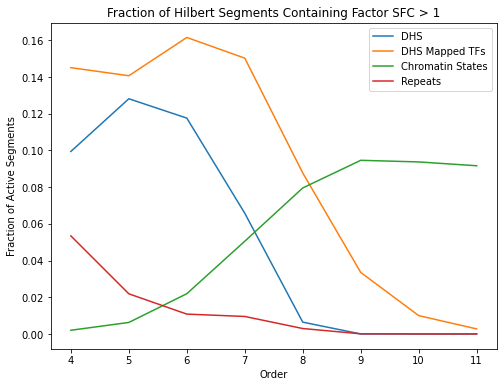

In [267]:
fig = plt.figure(figsize=(8, 6))  
fig.patch.set_facecolor('white')

plt.plot(range(4, len(dhs_segment_fraction_gt_thresh[:-1]) + 4), dhs_segment_fraction_gt_thresh[:-1])
plt.plot(range(4, len(tf_dhsmapped_segment_fraction_gt_thresh) + 4), tf_dhsmapped_segment_fraction_gt_thresh)
plt.plot(range(4, len(cs_segment_fraction_gt_thresh) + 4), cs_segment_fraction_gt_thresh)
plt.plot(range(4, len(repeats_segment_fraction_gt_thresh) + 4), repeats_segment_fraction_gt_thresh)

plt.xlabel('Order')
plt.ylabel('Fraction of Active Segments')
plt.legend(['DHS', 'DHS Mapped TFs', 'Chromatin States', 'Repeats'])
plt.title('Fraction of Hilbert Segments Containing Factor SFC > ' + str(thresh))

Text(0.5, 1.0, 'Average Segment Max (SCF > 1) Factor SFC Across Orders')

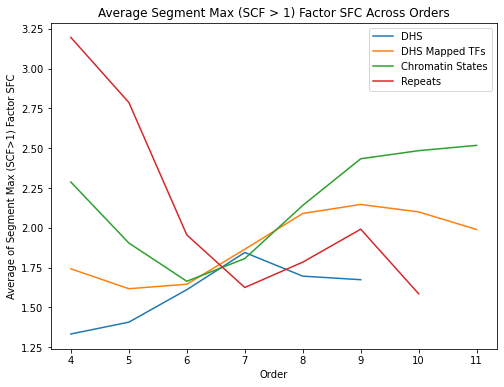

In [268]:
fig = plt.figure(figsize=(8, 6))  
fig.patch.set_facecolor('white')

plt.plot(range(4, len(dhs_maxaverage_gt_thresh[:-1]) + 4), dhs_maxaverage_gt_thresh[:-1])
plt.plot(range(4, len(tf_dhsmapped_maxaverage_gt_thresh) + 4), tf_dhsmapped_maxaverage_gt_thresh)
plt.plot(range(4, len(cs_maxaverage_gt_thresh) + 4), cs_maxaverage_gt_thresh)
plt.plot(range(4, len(repeats_maxaverage_gt_thresh) + 4), repeats_maxaverage_gt_thresh)

plt.xlabel('Order')
plt.ylabel('Average of Segment Max (SCF>1) Factor SFC')
plt.legend(['DHS', 'DHS Mapped TFs', 'Chromatin States', 'Repeats'])
plt.title('Average Segment Max (SCF > 1) Factor SFC Across Orders')

Text(0.5, 1.0, 'Average Segment Max Factor SFC Across Orders')

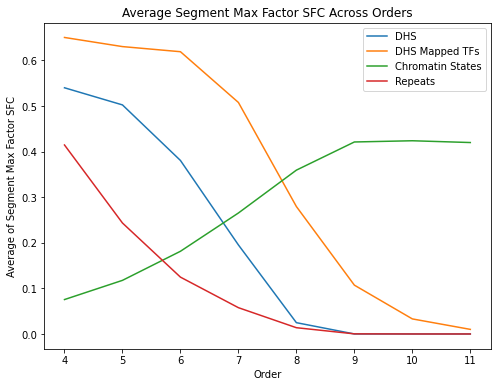

In [269]:
fig = plt.figure(figsize=(8, 6))  
fig.patch.set_facecolor('white')

plt.plot(range(4, len(dhs_maxaverage[:-1]) + 4), dhs_maxaverage[:-1])
plt.plot(range(4, len(tf_dhsmapped_maxaverage) + 4), tf_dhsmapped_maxaverage)
plt.plot(range(4, len(cs_maxaverage) + 4), cs_maxaverage)
plt.plot(range(4, len(repeats_maxaverage) + 4), repeats_maxaverage)

plt.xlabel('Order')
plt.ylabel('Average of Segment Max Factor SFC')
plt.legend(['DHS', 'DHS Mapped TFs', 'Chromatin States', 'Repeats'])
plt.title('Average Segment Max Factor SFC Across Orders')

Text(0.5, 1.0, 'Fraction of Hilbert Segments Containing Non-Zero Factor SFC')

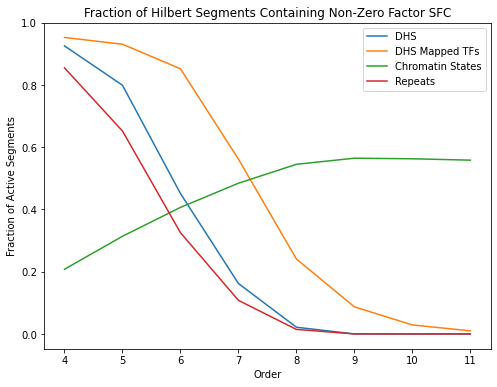

In [270]:
fig = plt.figure(figsize=(8, 6))  
fig.patch.set_facecolor('white')

plt.plot(range(4, len(dhs_segment_fraction_nonzero[:-1]) + 4), dhs_segment_fraction_nonzero[:-1])
plt.plot(range(4, len(tf_dhsmapped_segment_fraction_nonzero) + 4), tf_dhsmapped_segment_fraction_nonzero)
plt.plot(range(4, len(cs_segment_fraction_nonzero) + 4), cs_segment_fraction_nonzero)
plt.plot(range(4, len(repeats_segment_fraction_nonzero) + 4), repeats_segment_fraction_nonzero)

plt.xlabel('Order')
plt.ylabel('Fraction of Active Segments')
plt.legend(['DHS', 'DHS Mapped TFs', 'Chromatin States', 'Repeats'])
plt.title('Fraction of Hilbert Segments Containing Non-Zero Factor SFC')

Text(0.5, 0.93, 'Factors with >0 SFC Scores')

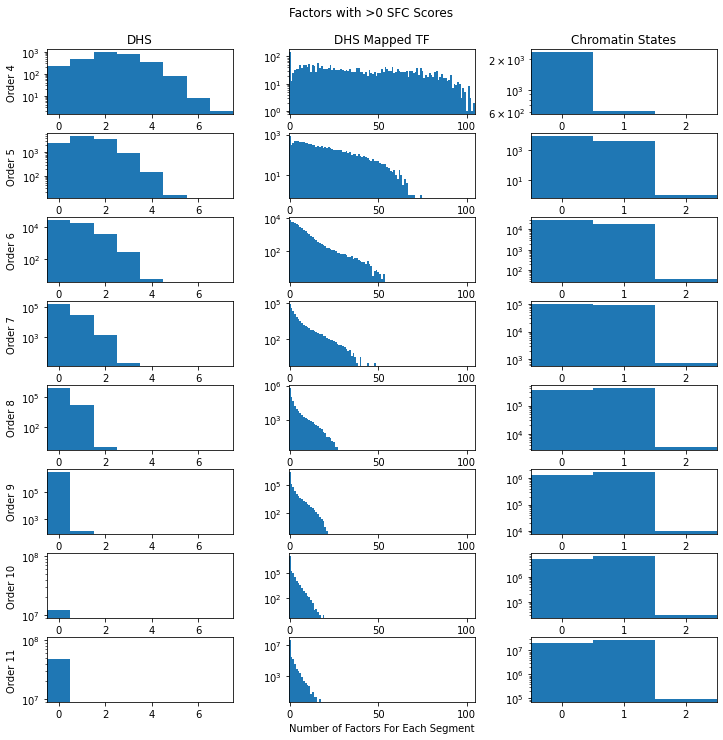

In [39]:
fig, axes = plt.subplots(nrows=8, ncols=3, figsize=(12, 12))
fig.patch.set_facecolor('white')
plt.subplots_adjust(wspace=0.3, hspace=0.3)

for order, i in zip(range(4, 12), range(8)):
    for data, j in zip([dhs_persegment_numfactors_nonzero, 
#                         tf_persegment_numfactors_nonzero, 
                        tf_dhsmapped_persegment_numfactors_nonzero, 
                        cs_persegment_numfactors_nonzero], 
                       range(3)):
        
        # get max value for datatype across orders
        m = 0
        for d in data:
            m = max(m, np.max(d))
            
        if len(data) > i:
            bc = np.bincount(data[i])
            axes[i, j].set_yscale('log')
            axes[i, j].bar(np.arange(len(bc)), bc, width=1)
            axes[i, j].set_xlim([-0.5, m + 0.5])
            axes[i, j].locator_params(axis='x', nbins=4)
        else:
            axes[i, j].set_xticks([])
            axes[i, j].set_yticks([])
        
    
    axes[i, 0].set_ylabel('Order %s' %order)

axes[0, 0].set_title('DHS')
# axes[0, 1].set_title('TF')
axes[0, 1].set_title('DHS Mapped TF')
axes[0, 2].set_title('Chromatin States')


# axes[0, 1].set_title('Fraction of Regions')
# axes[0, 1].legend(['All Regions', 'Search Space'])
axes[-1, 1].set_xlabel('Number of Factors For Each Segment')
plt.suptitle('Factors with >0 SFC Scores', y=0.93)

In [242]:
# kde plot showing the number of segments with a value at each order 
orders = [4, 5, 6, 7, 8, 9, 10, 11, 12]
filename = '/home/ctrader/hilbert/results/DHS/20230622/order_{}_windows_annotation_sfc_scores.txt.gz'.format(4)
dhs_factors = np.array(list(pd.read_csv(filename, delimiter='\t', usecols=np.arange(3, 16 + 3), nrows=0).columns))

dhs_factorXorder = np.zeros((len(dhs_factors), len(orders)))
dhs_num_segments = []
for i, order in enumerate(orders):
    t = time.time()
    filename = '/home/ctrader/hilbert/results/DHS/20230622/order_{}_windows_annotation_sfc_scores.txt.gz'.format(order)
    sfc = pd.read_csv(filename, delimiter='\t', usecols=np.arange(3, 16 + 3), dtype=np.float16)
    sfc = np.where(sfc < 0, 0, sfc)
    
    factor_counts = np.count_nonzero(sfc, axis=0)
    dhs_factorXorder[:, i] = factor_counts
    dhs_num_segments.append(len(sfc))
    
    del sfc
    print(order, time.time() - t)
dhs_num_segments = np.array(dhs_num_segments)

4 0.008208036422729492
5 0.02349996566772461
6 0.07433557510375977
7 0.2506382465362549
8 0.9368059635162354
9 3.757331371307373
10 15.092822074890137
11 60.621665477752686
12 244.27588820457458


In [243]:
dhs_factorXorder_fract = (dhs_factorXorder / dhs_num_segments)

In [244]:
dhs_y = pdist(dhs_factorXorder_fract, metric='euclidean')
dhs_Z = hierarchy.average(dhs_y)
dhs_Z_ordered = hierarchy.optimal_leaf_ordering(dhs_Z, dhs_y, metric='euclidean')
dhs_leaves = hierarchy.leaves_list(dhs_Z_ordered)

In [245]:
dhs_factorXorder_fract_norm = (dhs_factorXorder_fract.T / np.sum(dhs_factorXorder_fract, axis=1)).T

Text(0.5, 0.91, 'Significance for DHS Components, Euclidean Average Clustering')

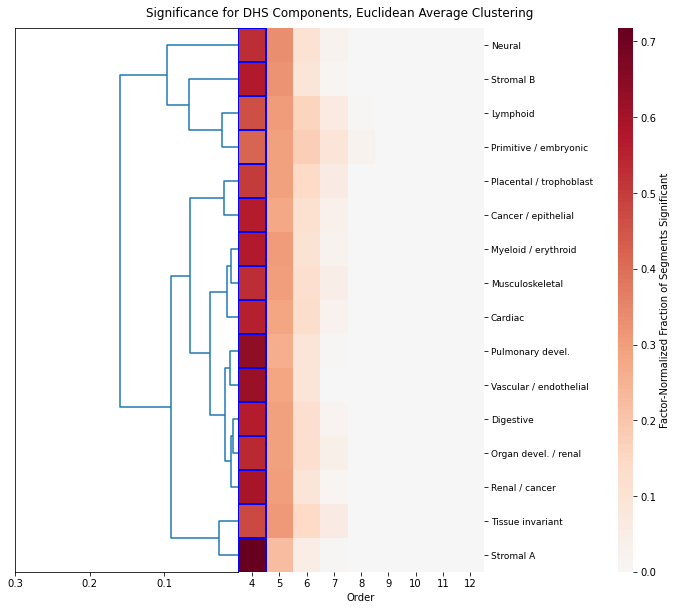

In [248]:
fig, axes = plt.subplots(1, 2, figsize=(12,10), gridspec_kw={'width_ratios': [1, 2]})  
fig.patch.set_facecolor('white')
plt.subplots_adjust(wspace=0)

axes.ravel()
d = hierarchy.dendrogram(dhs_Z_ordered, ax=axes[0], no_labels=True, color_threshold=0, orientation='left')

# have to flip leaves to match dendrogram
sns.heatmap(
    dhs_factorXorder_fract_norm[np.flip(dhs_leaves)], 
    ax=axes[1], 
    cmap='RdBu_r', 
    center=0, 
    vmax=np.max(dhs_factorXorder_fract_norm), # setting max below quiescent
    vmin=0, 
    cbar_kws={
        'label': 'Factor-Normalized Fraction of Segments Significant',
        'aspect': 35,
        'pad': 0.3
    }
)


for i, top_order in enumerate(np.argmax(dhs_factorXorder_fract_norm, axis=1)[np.flip(dhs_leaves)]):
    rect = plt.Rectangle((top_order, i), 1, 1, linewidth=2, edgecolor='blue', facecolor='none')
    plt.gca().add_patch(rect)

axes[0].set_xticks([0.3, 0.2, 0.1])


axes[1].set_xticks(np.arange(dhs_factorXorder_fract.shape[1]) + 0.5)
axes[1].set_xticklabels(np.arange(dhs_factorXorder_fract.shape[1]) + 4)
axes[1].set_xlabel('Order')


axes[1].yaxis.tick_right()
axes[1].set_yticks(np.arange(len(dhs_factors)) + 0.5)
axes[1].set_yticklabels(dhs_factors[np.flip(dhs_leaves)], rotation=0, fontsize=9)

fig.suptitle('Significance for DHS Components, Euclidean Average Clustering', y=0.91)

Which Chromatin State factors are best at each order

In [218]:
# kde plot showing the number of segments with a value at each order 
orders = [4, 5, 6, 7, 8, 9, 10]
filename = '/home/ctrader/hilbert/results/chromatin_states/20230622/order_{}_windows_annotation_sfc_scores.txt.gz'.format(4)
cs_factors = np.array(list(pd.read_csv(filename, delimiter='\t', usecols=np.arange(3, 18 + 3), nrows=0).columns))

cs_factorXorder = np.zeros((len(cs_factors), len(orders)))
cs_num_segments = []
for i, order in enumerate(orders):
    t = time.time()
    filename = '/home/ctrader/hilbert/results/chromatin_states/20230622/order_{}_windows_annotation_sfc_scores.txt.gz'.format(order)
    sfc = pd.read_csv(filename, delimiter='\t', usecols=np.arange(3, 18 + 3), dtype=np.float16)
    sfc = np.where(sfc < 0, 0, sfc)
    
    factor_counts = np.count_nonzero(sfc, axis=0)
    cs_factorXorder[:, i] = factor_counts
    cs_num_segments.append(len(sfc))
    
    del sfc
    print(order, time.time() - t)
cs_num_segments = np.array(cs_num_segments)

4 0.0073015689849853516
5 0.023921966552734375
6 0.08033299446105957
7 0.29273414611816406
8 1.1814703941345215
9 4.562866687774658
10 18.532344102859497


In [219]:
np.argmax(cs_factorXorder, axis=1)

array([6, 6, 6, 6, 6, 6, 5, 6, 6, 6, 6, 6, 6, 6, 5, 6, 6, 6])

In [220]:
cs_factorXorder_fract = (cs_factorXorder / cs_num_segments)

In [221]:
cs_y = pdist(cs_factorXorder_fract, metric='euclidean')
cs_Z = hierarchy.average(cs_y)
cs_Z_ordered = hierarchy.optimal_leaf_ordering(cs_Z, cs_y, metric='euclidean')
cs_leaves = hierarchy.leaves_list(cs_Z_ordered)

In [222]:
cs_factorXorder_fract_norm = (cs_factorXorder_fract.T / np.sum(cs_factorXorder_fract, axis=1)).T

Text(0.5, 0.91, 'Significance for Chromatin States, Euclidean Average Clustering')

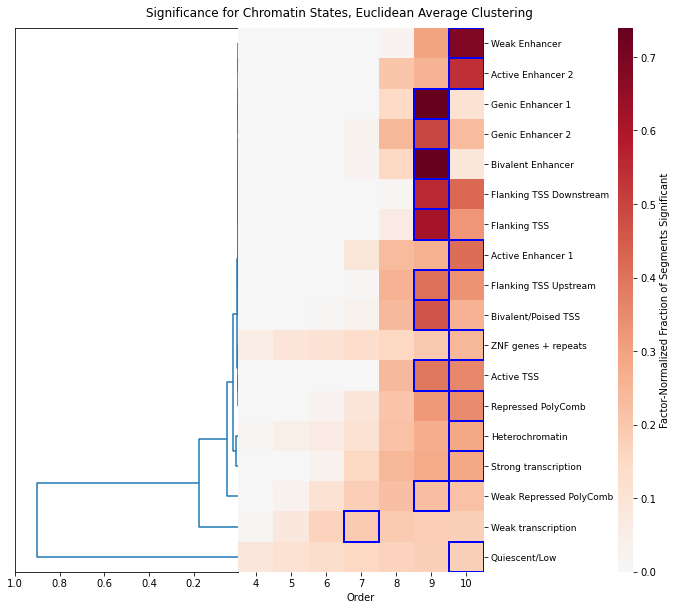

In [225]:
fig, axes = plt.subplots(1, 2, figsize=(12,10), gridspec_kw={'width_ratios': [1, 2]})  
fig.patch.set_facecolor('white')
plt.subplots_adjust(wspace=0)

axes.ravel()
d = hierarchy.dendrogram(cs_Z_ordered, ax=axes[0], no_labels=True, color_threshold=0, orientation='left')

# have to flip leaves to match dendrogram
sns.heatmap(
    cs_factorXorder_fract_norm[np.flip(cs_leaves)], 
    ax=axes[1], 
    cmap='RdBu_r', 
    center=0, 
    vmax=np.max(cs_factorXorder_fract_norm), # setting max below quiescent
    vmin=0, 
    cbar_kws={
        'label': 'Factor-Normalized Fraction of Segments Significant',
        'aspect': 35,
        'pad': 0.3
    }
)


for i, top_order in enumerate(np.argmax(cs_factorXorder_fract_norm, axis=1)[np.flip(cs_leaves)]):
    rect = plt.Rectangle((top_order, i), 1, 1, linewidth=2, edgecolor='blue', facecolor='none')
    plt.gca().add_patch(rect)

axes[0].set_xticks([1, 0.8, 0.6, 0.4, 0.2])


axes[1].set_xticks(np.arange(cs_factorXorder_fract.shape[1]) + 0.5)
axes[1].set_xticklabels(np.arange(cs_factorXorder_fract.shape[1]) + 4)
axes[1].set_xlabel('Order')


axes[1].yaxis.tick_right()
axes[1].set_yticks(np.arange(len(cs_factors)) + 0.5)
axes[1].set_yticklabels(cs_factors[np.flip(cs_leaves)], rotation=0, fontsize=9)

fig.suptitle('Significance for Chromatin States, Euclidean Average Clustering', y=0.91)

In [239]:
datadir = '/home/ctrader/region_similarity/data/rank_based/hilbert/sfc/20230718/'
f = h5py.File(os.path.join(datadir, 'hilbert_regions_order_4_CT20230718.cs.sfc.ranks.hdf5'), 'r')
cs_colors = np.char.decode(f['colors'][:])
f.close()
cs_colors[-1] = '#d9d9d9'

Text(0.5, 1.0, 'Chromatin States: Factor-Normalized Fraction of Segments Significant')

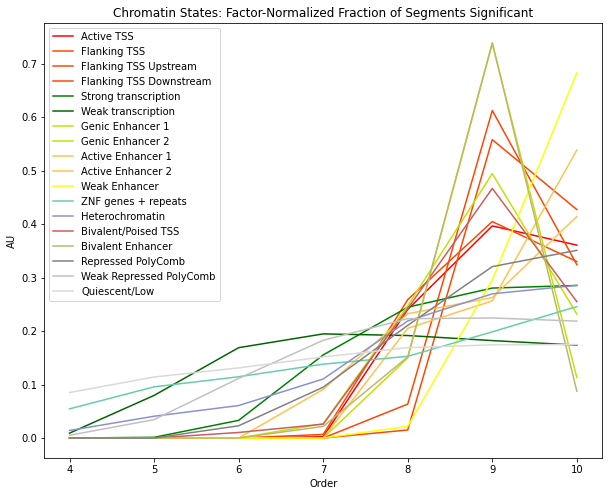

In [241]:
fig = plt.figure(figsize=(10, 8))  
fig.patch.set_facecolor('white')

for data, color in zip(cs_factorXorder_fract_norm, cs_colors):
    plt.plot(range(4, len(data) + 4), data, c=color)

plt.xlabel('Order')
plt.ylabel('AU')
plt.legend(cs_factors)
plt.title('Chromatin States: Factor-Normalized Fraction of Segments Significant')

Which TF factors are best at each order

In [100]:
# kde plot showing the number of segments with a value at each order 
orders = [4, 5, 6, 7, 8, 9, 10, 11]
filename = '/home/ctrader/hilbert/results/TFs_overlapping_DHS/20230622/order_{}_windows_annotation_sfc_scores.txt.gz'.format(4)
tf_factors = np.array(list(pd.read_csv(filename, delimiter='\t', usecols=np.arange(3, 282 + 3), nrows=0).columns))

tf_dhsmapped_factorXorder = np.zeros((len(tf_factors), len(orders)))
tf_num_segments = []
for i, order in enumerate(range(4, 12)):
    t = time.time()
    filename = '/home/ctrader/hilbert/results/TFs_overlapping_DHS/20230622/order_{}_windows_annotation_sfc_scores.txt.gz'.format(order)
    sfc = pd.read_csv(filename, delimiter='\t', usecols=np.arange(3, 282 + 3), dtype=np.float16)
    sfc = np.where(sfc < 0, 0, sfc)
    
    factor_counts = np.count_nonzero(sfc, axis=0)
    tf_dhsmapped_factorXorder[:, i] = factor_counts
    tf_num_segments.append(len(sfc))
    
    del sfc
    print(order, time.time() - t)
tf_num_segments = np.array(tf_num_segments)

4 0.13052010536193848
5 0.40516161918640137
6 1.4660990238189697
7 5.636235237121582
8 22.65363883972168
9 88.43522500991821
10 351.56870102882385
11 1443.1919107437134


In [112]:
y = pdist((tf_dhsmapped_factorXorder / tf_num_segments), metric='euclidean')
Z = hierarchy.average(y)
Z_ordered = hierarchy.optimal_leaf_ordering(Z, y, metric='euclidean')
leaves = hierarchy.leaves_list(Z_ordered)

Text(0.5, 0.89, 'Significance for TF Motifs, Euclidean Average Clustering')

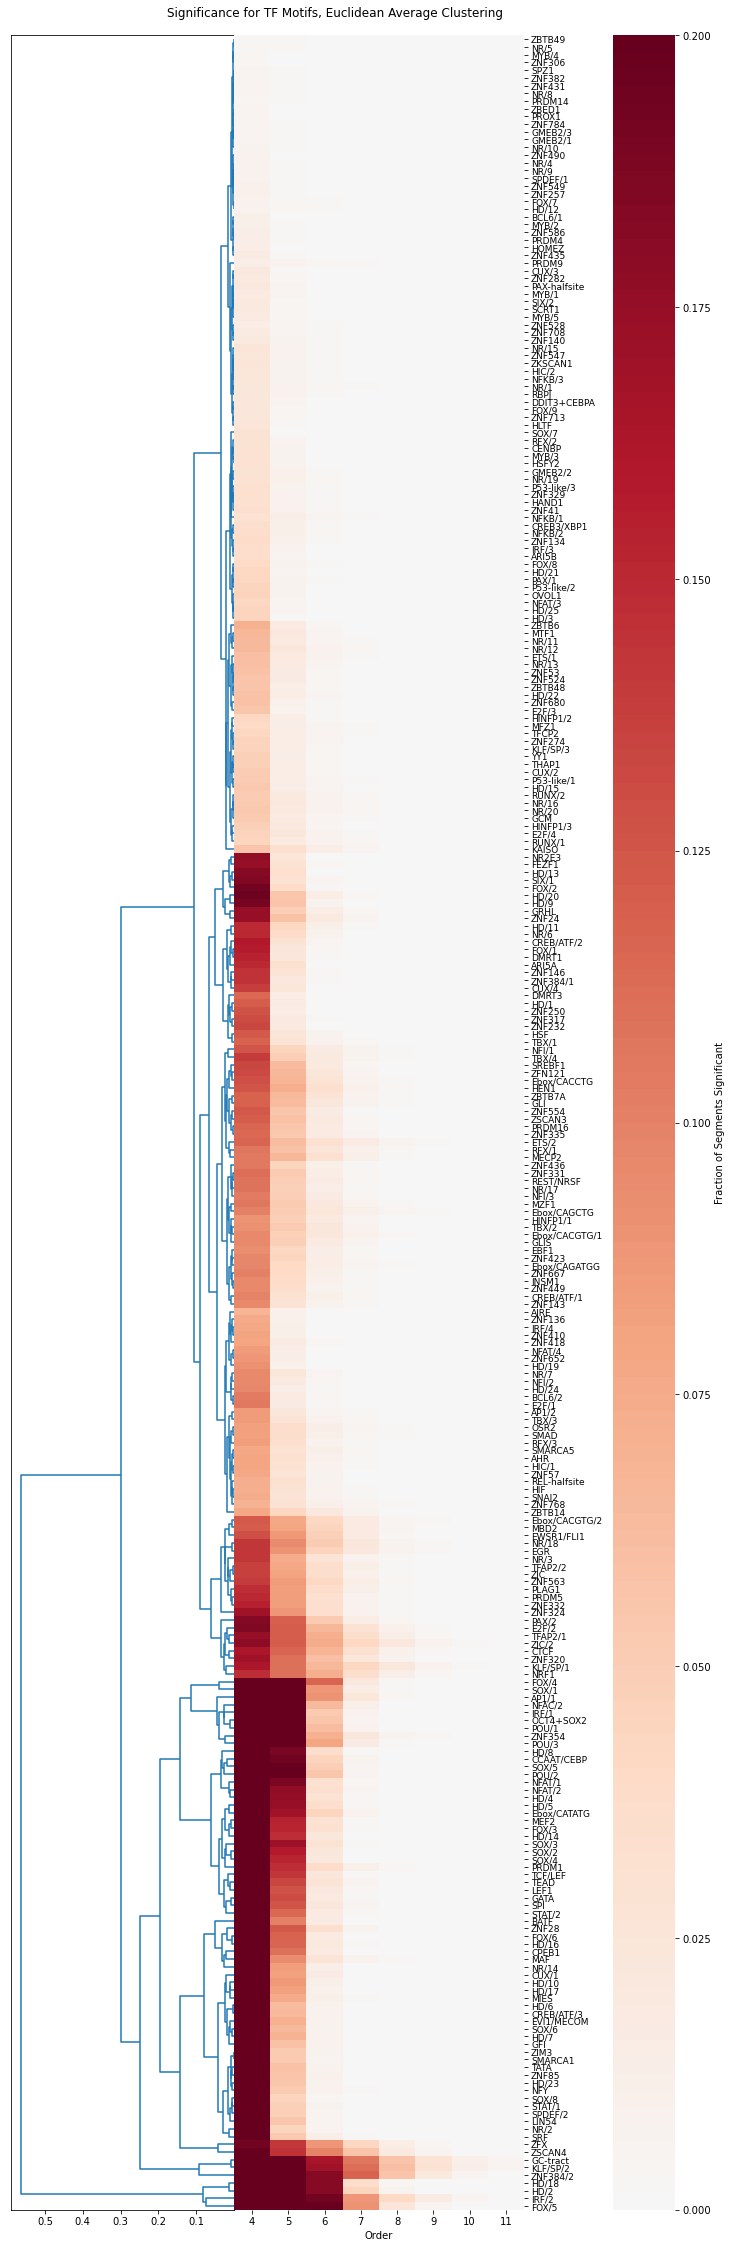

In [158]:
fig, axes = plt.subplots(1, 2, figsize=(12, 40), gridspec_kw={'width_ratios': [1, 2]})  
fig.patch.set_facecolor('white')
plt.subplots_adjust(wspace=0)

axes.ravel()
d = hierarchy.dendrogram(Z_ordered, ax=axes[0], no_labels=True, color_threshold=0, orientation='left')

# have to flip leaves to match dendrogram
sns.heatmap(
    (tf_dhsmapped_factorXorder / tf_num_segments)[np.flip(leaves)], 
    ax=axes[1], 
    cmap='RdBu_r', 
    center=0, 
#     vmax=np.max(tf_dhsmapped_factorXorder / tf_num_segments) / 2,
    vmax = 0.2,
    vmin=0, 
    cbar_kws={
        'label': 'Fraction of Segments Significant',
        'aspect': 35,
        'pad': 0.2
    }
)

axes[0].set_xticks([0.5, 0.4, 0.3, 0.2, 0.1])


axes[1].set_xticks(np.arange(tf_dhsmapped_factorXorder.shape[1]) + 0.5)
axes[1].set_xticklabels(np.arange(tf_dhsmapped_factorXorder.shape[1]) + 4)
axes[1].set_xlabel('Order')


axes[1].yaxis.tick_right()
axes[1].set_yticks(np.arange(len(tf_factors)) + 0.5)
axes[1].set_yticklabels(tf_factors[np.flip(leaves)], rotation=0, fontsize=9)

fig.suptitle('Significance for TF Motifs, Euclidean Average Clustering', y=0.89)

Creating -e file for chromatin states

In [10]:
# datadir = '/home/ctrader/chromatin_states/'
# filepath = os.path.join(datadir, 'state_counts_CT20230622.c2.txt')

# x = np.loadtxt(filepath, dtype=int)

In [12]:
# np.sum(x) / 833

**Resubmit combination jobs that fail**

In [88]:
import subprocess
def submitSlurmJob(jobName, pythonCommand, outputDir, partition, memory, dependency=""):
    """
    Submits a slurm job to the cluster using the subprocess module

    Input:
    jobName       -- Name of the job to run
    pythonCommand -- Command to be submitted using sbatch
    outputDir     -- pathlib Path to the output directory for similarity search files
    partition     -- Slurm partition to use as string formatted with slurm flag
    memory        -- Memory to be allocated to the job as a string formatted with slurm flag
    dependency    -- Which jobs the SLURM job must wait for before starting

    Output:
    int(sp.stdout.split()[-1]) -- Slurm jobID number
    """
    jobOutPath = os.path.join(outputDir, (".out/" + jobName + ".out"))
    jobErrPath = os.path.join(outputDir, (".err/" + jobName + ".err"))


    command = "sbatch {} --job-name={}.job --output={} --error={} {} {} --wrap='{}'".format(dependency, jobName,
                                                                                         jobOutPath, jobErrPath,
                                                                                         partition, memory,
                                                                                         pythonCommand)
    sp = subprocess.run(command, shell=True, check=True, universal_newlines=True, stdout=subprocess.PIPE)

    if not sp.stdout.startswith("Submitted batch"):
        raise ChildProcessError("SlurmError: sbatch not submitted correctly")

    return sp.stdout.split()[-1]


In [89]:
py_files_dir = '/home/ctrader/AG/hilbert/hilbertgenome-py/'
output_dir = '/home/ctrader/hilbert/results/cpg_islands/20230720/'
order=11
num_jobs=20
output_txt=True
slurm_mem=200000
partition="pool,queue0"
py_command = f"python {os.path.join(py_files_dir, 'combine_sfc_results_lowmem.py')} {output_dir} {order} {num_jobs} {output_txt}"

In [90]:
py_command

'python /home/ctrader/AG/hilbert/hilbertgenome-py/combine_sfc_results_lowmem.py /home/ctrader/hilbert/results/cpg_islands/20230720/ 11 20 True'

In [91]:
submitSlurmJob(f"combine_sfc_order_{order}_lowmem", py_command, output_dir, f"--partition={partition}", f"--mem={slurm_mem}")

'40433426'

**Correlation analysis**

In [281]:
from scipy.stats import spearmanr, pearsonr

In [331]:
def get_correlation(datadir1, method1, datadir2, method2):
    arr = []
    for order in range(4,10):
        # dataset 1
        filename = 'order_{}_windows_annotations.{}.txt'.format(order, method1)
        data1 = np.loadtxt(os.path.join(datadir1, filename), skiprows=1, dtype=float, usecols=3)
        data1 = np.where(np.isnan(data1), 0, data1)
        
        # dataset 2
        filename = 'order_{}_windows_annotations.{}.txt'.format(order, method2)
        data2 = np.loadtxt(os.path.join(datadir2, filename), skiprows=1, dtype=float, usecols=3)
        data2 = np.where(np.isnan(data2), 0, data2)

        # correlation
        arr.append(spearmanr(data1, data2).statistic)
    return arr

In [339]:
coregBestScaleDensityXgencodeDensity = get_correlation(
    '/home/ctrader/hilbert/results/gencode/density/20230803/', 
    'count',
    '/home/ctrader/hilbert/results/DHS/coregBestScale/density/20230803',
    'count'
)
coregBestScaleMaxXgencodeDensity = get_correlation(
    '/home/ctrader/hilbert/results/gencode/density/20230803/', 
    'count',
    '/home/ctrader/hilbert/results/DHS/coregBestScale/max/20230803/',
    'max'
)

In [340]:
coregBestScaleDensityXcpgDensity= get_correlation(
    '/home/ctrader/hilbert/results/cpg_islands/20230724/', 
    'count',
    '/home/ctrader/hilbert/results/DHS/coregBestScale/density/20230803',
    'count'
)
coregBestScaleMaxXcpgDensity = get_correlation(
    '/home/ctrader/hilbert/results/cpg_islands/20230724/', 
    'count',
    '/home/ctrader/hilbert/results/DHS/coregBestScale/max/20230803/',
    'max'
)

In [341]:
coregBestScaleDensityXdhsDensity = get_correlation(
    '/home/ctrader/hilbert/results/DHS/density/20230724/', 
    'count',
    '/home/ctrader/hilbert/results/DHS/coregBestScale/density/20230803',
    'count'
)
coregBestScaleMaxXdhsDensity = get_correlation(
    '/home/ctrader/hilbert/results/DHS/density/20230724/', 
    'count',
    '/home/ctrader/hilbert/results/DHS/coregBestScale/max/20230803/',
    'max'
)

In [342]:
coregBestScaleDensityXdhsMax = get_correlation(
    '/home/ctrader/hilbert/results/DHS/maxsignal/20230724/', 
    'max',
    '/home/ctrader/hilbert/results/DHS/coregBestScale/density/20230803',
    'count'
)
coregBestScaleMaxXdhsMax = get_correlation(
    '/home/ctrader/hilbert/results/DHS/maxsignal/20230724/', 
    'max',
    '/home/ctrader/hilbert/results/DHS/coregBestScale/max/20230803/',
    'max'
)

Text(0.5, 1.0, 'DHS Coregulation Correlation with Density and Signal Datasets')

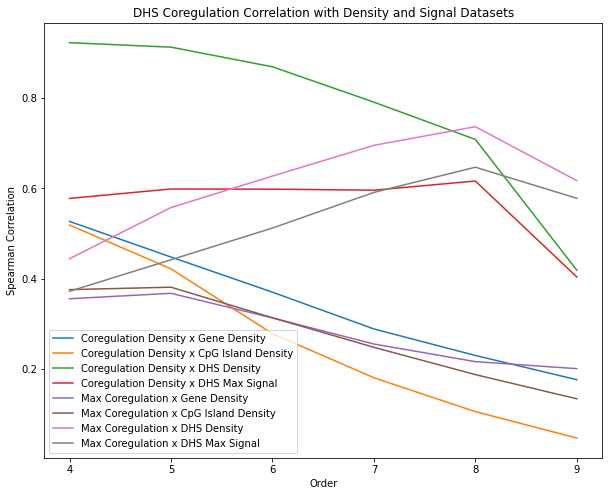

In [350]:
fig = plt.figure(figsize=(10, 8))  
fig.patch.set_facecolor('white')

plt.plot(range(4, len(coregBestScaleDensityXgencodeDensity) + 4), coregBestScaleDensityXgencodeDensity)
plt.plot(range(4, len(coregBestScaleDensityXcpgDensity) + 4), coregBestScaleDensityXcpgDensity)
plt.plot(range(4, len(coregBestScaleDensityXdhsDensity) + 4), coregBestScaleDensityXdhsDensity)
plt.plot(range(4, len(coregBestScaleDensityXdhsMax) + 4), coregBestScaleDensityXdhsMax)
plt.plot(range(4, len(coregBestScaleMaxXgencodeDensity) + 4), coregBestScaleMaxXgencodeDensity)
plt.plot(range(4, len(coregBestScaleMaxXcpgDensity) + 4), coregBestScaleMaxXcpgDensity)
plt.plot(range(4, len(coregBestScaleMaxXdhsDensity) + 4), coregBestScaleMaxXdhsDensity)
plt.plot(range(4, len(coregBestScaleMaxXdhsMax) + 4), coregBestScaleMaxXdhsMax)


plt.xlabel('Order')
plt.ylabel('Spearman Correlation')
legend = [
    'Coregulation Density x Gene Density',
    'Coregulation Density x CpG Island Density',
    'Coregulation Density x DHS Density',
    'Coregulation Density x DHS Max Signal',
    'Max Coregulation x Gene Density',
    'Max Coregulation x CpG Island Density',
    'Max Coregulation x DHS Density',
    'Max Coregulation x DHS Max Signal'
]
plt.legend(legend)
plt.title('DHS Coregulation Correlation with Density and Signal Datasets')